# Asistente RAG para servicios de posgrado en Icesi

## Problema y alcance

Quien estudia o considera estudiar un posgrado puede tener que revisar varias páginas para encontrar información sobre servicios, admisiones, pagos, acompañamiento y biblioteca. Este proyecto construye un prototipo que recupera fragmentos de páginas públicas de la Universidad Icesi y genera respuestas en español que muestran las fuentes consultadas.

**Pregunta de investigación:** ¿cómo cambia la recuperación de información cuando comparamos BM25 (búsqueda léxica) con embeddings multilingües, y cómo influye el tamaño de los fragmentos en un asistente RAG sobre páginas institucionales?

**Hipótesis:** los embeddings podrían recuperar páginas pertinentes cuando la pregunta y la página expresan la misma idea con palabras distintas; BM25 podría ser competitivo ante nombres propios y términos exactos. El efecto del tamaño de fragmento se medirá, no se supondrá.

**Alcance deliberado:** las fuentes incluyen páginas públicas sobre servicios y procesos de posgrado y la Resolución 1691 de 2026, que modifica el reglamento de posgrado. No se dispone del reglamento completo ni de un calendario académico oficial; el asistente solo puede responder sobre la resolución cuando el fragmento recuperado lo sustente y no debe inventar otras normas o fechas. Ante falta de evidencia, debe reconocer el límite y dirigir al usuario a la fuente oficial.

El prototipo compara métodos de recuperación y tamaños de fragmento mediante métricas cuantitativas, y analiza sus resultados junto con las limitaciones de cobertura y generación.


## Cómo ejecutar en Google Colab

1. Sube este archivo a Colab y selecciona **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**.
2. Ejecuta las celdas en orden. La primera instalación, la descarga de las páginas oficiales y los modelos requieren internet.
3. Revisa en la salida de carga qué fuentes se descargaron y cuáles fallaron. El notebook reporta fallos y se detiene si ninguna página puede cargarse.
4. Inspecciona el EDA y las consultas anotadas; luego compara recuperación léxica y semántica en validación y prueba.
5. La descarga de Qwen2.5-1.5B-Instruct requiere varios GB y una GPU acelera la generación. La ejecución en CPU puede ser lenta.
6. Ejecuta al final la interfaz Gradio y prueba preguntas respondibles y no respondibles. Para la entrega, graba la ejecución y un par de interacciones con las referencias visibles.

Las páginas institucionales pueden cambiar o limitar el acceso automatizado. Conserva en el informe la fecha de consulta, las fuentes fallidas y cualquier ajuste que realices. No presentes respuestas del modelo como hechos verificados sin contrastarlas con los enlaces citados.

In [1]:
%pip -q install beautifulsoup4 pypdf rank-bm25 sentence-transformers transformers accelerate gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 10.3 MB/s eta 0:00:00


In [2]:
import re
import random
import time
from io import BytesIO
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from bs4 import BeautifulSoup
from pypdf import PdfReader
from IPython.display import display
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo disponible: {DEVICE}")
print(f"Consulta de fuentes: {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}")

Dispositivo disponible: cuda
Consulta de fuentes: 2026-10-11 05:05 UTC


## Fuentes y descarga

El corpus combina páginas oficiales de `icesi.edu.co` con la Resolución 1691 de 2026, que modifica el reglamento de posgrado. El PDF se procesa localmente con `pypdf`; se conserva el enlace oficial como referencia. No se dispone del reglamento completo ni del calendario académico. La descarga por web puede cambiar o ser bloqueada, por eso se informa el estado de cada fuente.

In [3]:
SOURCES = [
    {"source_id": "portal_estudiantes", "title": "Portal de estudiantes", "url": "https://www.icesi.edu.co/estudiantes/"},
    {"source_id": "servicios_posgrado", "title": "Servicios para estudiantes de posgrado", "url": "https://www.icesi.edu.co/estudiantes-posgrado-centro-de-talento-icesi/"},
    {"source_id": "admisiones_posgrado", "title": "Admisiones de posgrado", "url": "https://www.icesi.edu.co/admisiones-de-posgrado/"},
    {"source_id": "inscripcion_pago", "title": "Inscripción y forma de pago de posgrados", "url": "https://www.icesi.edu.co/inscripcion-y-forma-de-pago-posgrados/"},
    {"source_id": "asesores_posgrado", "title": "Asesores de posgrados", "url": "https://www.icesi.edu.co/asesores-posgrados/"},
    {"source_id": "acompanamiento", "title": "Ecosistema de acompañamiento a estudiantes", "url": "https://www.icesi.edu.co/decanatura-de-innovacion-educativa-y-fortalecimiento-del-pei/ecosistema-de-acompanamiento-a-estudiantes/"},
    {"source_id": "biblioteca", "title": "Biblioteca Icesi", "url": "https://www.icesi.edu.co/biblioteca/"},
    {"source_id": "bienestar", "title": "Bienestar Universitario: programa Estas en Casa", "url": "https://www.icesi.edu.co/bienestar-universitario/programa-estas-en-casa/"},
    {"source_id": "reglamento_posgrado_res_1691", "title": "Resolución 1691 de 2026: modifica el reglamento de posgrado", "url": "https://www.icesi.edu.co/wp-content/uploads/2026/04/Reso-1691-Modifica-reglamento-de-posgrado.pdf", "format": "pdf"},
]

def extract_page_text(html):
    soup = BeautifulSoup(html, "html.parser")
    for element in soup.select("script, style, noscript, svg, nav, footer, header, form"):
        element.decompose()
    candidates = [soup.select_one(selector) for selector in ("main", "article", ".entry-content", ".wp-block-post-content", "body")]
    candidates = [element for element in candidates if element is not None]
    container = max(candidates, key=lambda element: len(element.get_text(" ", strip=True))) if candidates else soup
    pieces = []
    for element in container.select("h1, h2, h3, h4, p, li"):
        text = re.sub(r"\s+", " ", element.get_text(" ", strip=True)).strip()
        if len(text) >= 25 and (not pieces or text != pieces[-1]):
            pieces.append(text)
    return "\n".join(pieces)

def extract_pdf_text(pdf_bytes):
    reader = PdfReader(BytesIO(pdf_bytes))
    page_texts = []
    for page_number, page in enumerate(reader.pages, start=1):
        text = re.sub(r"\s+", " ", page.extract_text() or "").strip()
        if text:
            page_texts.append(f"Página {page_number}: {text}")
    return "\n".join(page_texts)

documents = []
source_status = []
headers = {"User-Agent": "Mozilla/5.0 (compatible; IcesiRAGStudentProject/1.0)"}
for source in SOURCES:
    try:
        response = requests.get(source["url"], headers=headers, timeout=25)
        response.raise_for_status()
        if source.get("format") == "pdf":
            if not response.content.startswith(b"%PDF"):
                raise ValueError("La URL respondió, pero el contenido no parece ser un PDF.")
            text = extract_pdf_text(response.content)
        else:
            text = extract_page_text(response.text)
        if len(text.split()) < 20:
            raise ValueError(f"La página devolvió muy poco texto extraíble ({len(text.split())} palabras).")
        documents.append({**source, "text": text})
        source_status.append({"source_id": source["source_id"], "status": "OK", "words": len(text.split()), "url": source["url"]})
    except (requests.RequestException, ValueError) as error:
        source_status.append({"source_id": source["source_id"], "status": f"ERROR: {error}", "words": 0, "url": source["url"]})
    time.sleep(0.3)

failed_source_ids = {item["source_id"] for item in source_status if item["status"] != "OK"}
if failed_source_ids:
    from google.colab import files
    print("\nAlgunas páginas bloquearon la descarga automatizada (por ejemplo, HTTP 403).")
    print("Desde tu navegador, guarda las páginas fallidas como HTML; para la resolución descarga el PDF original. Súbelos cuando aparezca el selector.")
    sources_by_id = {source["source_id"]: source for source in SOURCES}
    expected_names = [f"{source_id}.{'pdf' if sources_by_id[source_id].get('format') == 'pdf' else 'html'}" for source_id in sorted(failed_source_ids)]
    print("Usa estos nombres de archivo: " + ", ".join(expected_names))
    uploaded_files = files.upload()
    for filename, content in uploaded_files.items():
        source_id = filename.rsplit("/", 1)[-1].rsplit(".", 1)[0]
        if source_id not in failed_source_ids:
            print(f"Se omite {filename}: el nombre no corresponde a una fuente fallida.")
            continue
        source = sources_by_id[source_id]
        if source.get("format") == "pdf":
            if not filename.lower().endswith(".pdf") or not content.startswith(b"%PDF"):
                print(f"Se omite {filename}: esta fuente requiere el PDF original.")
                continue
            text = extract_pdf_text(content)
        else:
            if not filename.lower().endswith((".html", ".htm")):
                print(f"Se omite {filename}: esta fuente requiere una página .html o .htm.")
                continue
            html = content.decode("utf-8", errors="replace")
            text = extract_page_text(html)
        if len(text.split()) < 20:
            source_status.append({"source_id": source_id, "status": "ERROR: el HTML subido contiene menos de 20 palabras extraíbles", "words": 0, "url": sources_by_id[source_id]["url"]})
            continue
        documents.append({**source, "text": text})
        source_status.append({"source_id": source_id, "status": "OK (HTML subido manualmente)", "words": len(text.split()), "url": source["url"]})

status_df = pd.DataFrame(source_status).drop_duplicates(subset="source_id", keep="last")
display(status_df)
if not documents:
    raise RuntimeError("No fue posible extraer texto de ninguna fuente. Comprueba tu conexión y sube las páginas oficiales guardadas como HTML y la resolución como PDF con los nombres de fuente indicados.")

documents_df = pd.DataFrame(documents)
print(f"\nDocumentos utilizables: {len(documents_df)} de {len(SOURCES)}")
print("Los fallos de carga anteriores no se descartan: documenta su efecto en la cobertura del corpus.")

,source_id,status,words,url
0,portal_estudiantes,OK,886,https://www.icesi.edu.co/estudiantes/
1,servicios_posgrado,OK,66,https://www.icesi.edu.co/estudiantes-posgrado-...
2,admisiones_posgrado,OK,1427,https://www.icesi.edu.co/admisiones-de-posgrado/
3,inscripcion_pago,OK,70,https://www.icesi.edu.co/inscripcion-y-forma-d...
4,asesores_posgrado,OK,221,https://www.icesi.edu.co/asesores-posgrados/
5,acompanamiento,OK,683,https://www.icesi.edu.co/decanatura-de-innovac...
6,biblioteca,OK,60,https://www.icesi.edu.co/biblioteca/
7,bienestar,OK,208,https://www.icesi.edu.co/bienestar-universitar...
8,reglamento_posgrado_res_1691,OK,12938,https://www.icesi.edu.co/wp-content/uploads/20...



Documentos utilizables: 9 de 9
Los fallos de carga anteriores no se descartan: documenta su efecto en la cobertura del corpus.


## EDA del corpus

Este EDA describe el corpus descargado en esta ejecución: cobertura por fuente, longitud y posibles páginas demasiado cortas. Las cantidades pueden variar cuando Icesi actualice su sitio o cambie la extracción. Con un corpus web pequeño, interpreta los gráficos como diagnóstico de cobertura, no como una caracterización estadística de toda la universidad.

,source_id,title,word_count,char_count,paragraph_count,url
8,reglamento_posgrado_res_1691,Resolución 1691 de 2026: modifica el reglament...,12938,82697,35,https://www.icesi.edu.co/wp-content/uploads/20...
2,admisiones_posgrado,Admisiones de posgrado,1427,10022,60,https://www.icesi.edu.co/admisiones-de-posgrado/
0,portal_estudiantes,Portal de estudiantes,886,6309,59,https://www.icesi.edu.co/estudiantes/
5,acompanamiento,Ecosistema de acompañamiento a estudiantes,683,5057,16,https://www.icesi.edu.co/decanatura-de-innovac...
4,asesores_posgrado,Asesores de posgrados,221,1668,35,https://www.icesi.edu.co/asesores-posgrados/
7,bienestar,Bienestar Universitario: programa Estas en Casa,208,1223,18,https://www.icesi.edu.co/bienestar-universitar...
3,inscripcion_pago,Inscripción y forma de pago de posgrados,70,440,8,https://www.icesi.edu.co/inscripcion-y-forma-d...
1,servicios_posgrado,Servicios para estudiantes de posgrado,66,473,8,https://www.icesi.edu.co/estudiantes-posgrado-...
6,biblioteca,Biblioteca Icesi,60,405,2,https://www.icesi.edu.co/biblioteca/


Palabras totales: 16,559
Mediana de palabras por página: 221.0
Páginas con menos de 100 palabras: 3 de 9


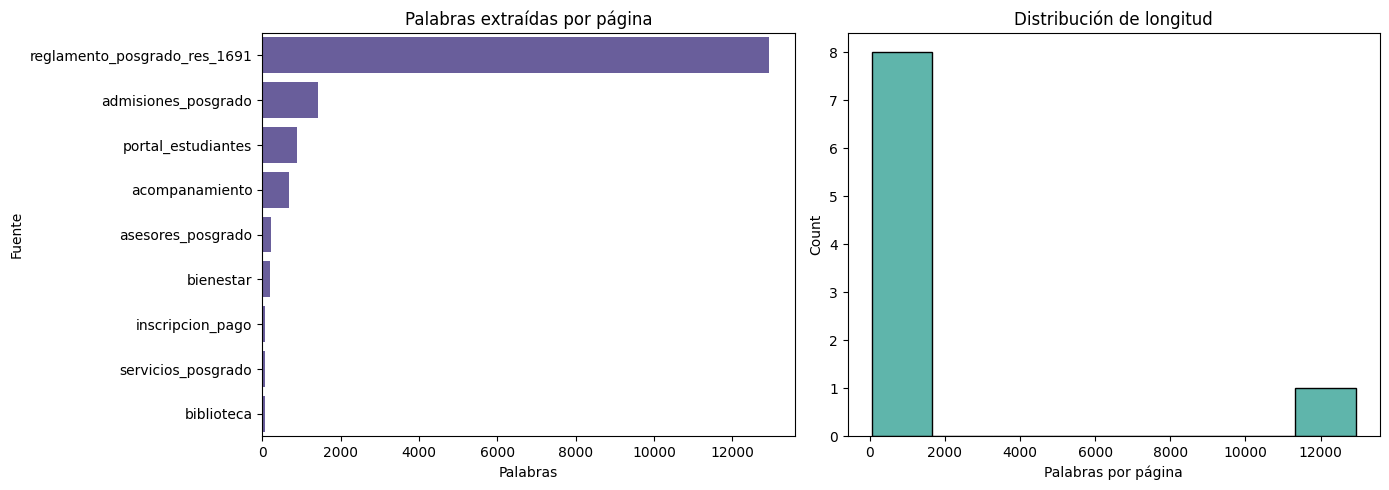

In [4]:
documents_df["word_count"] = documents_df["text"].str.split().str.len()
documents_df["char_count"] = documents_df["text"].str.len()
documents_df["paragraph_count"] = documents_df["text"].str.count("\n") + 1
display(documents_df[["source_id", "title", "word_count", "char_count", "paragraph_count", "url"]].sort_values("word_count", ascending=False))
print(f"Palabras totales: {documents_df['word_count'].sum():,}")
print(f"Mediana de palabras por página: {documents_df['word_count'].median():.1f}")
print(f"Páginas con menos de 100 palabras: {(documents_df['word_count'] < 100).sum()} de {len(documents_df)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=documents_df.sort_values("word_count", ascending=False), x="word_count", y="source_id", ax=axes[0], color="#6254a5")
axes[0].set_title("Palabras extraídas por página")
axes[0].set_xlabel("Palabras")
axes[0].set_ylabel("Fuente")
sns.histplot(documents_df["word_count"], bins=min(8, len(documents_df)), ax=axes[1], color="#2a9d8f")
axes[1].set_title("Distribución de longitud")
axes[1].set_xlabel("Palabras por página")
plt.tight_layout()
plt.show()

## Fragmentación: dos configuraciones

Se comparan fragmentos de 120 y 240 palabras, con solapamientos de 25 y 40 palabras respectivamente. Mantener título e identificador de fuente en cada fragmento permite entender el contexto recuperado y devolver una referencia. Si el EDA muestra que la mayoría de páginas es corta, es posible que distintas configuraciones produzcan fragmentos similares; ese resultado también es informativo.

In [5]:
CHUNK_CONFIGS = [(120, 25), (240, 40)]

def make_chunks(records, chunk_size, overlap):
    chunks = []
    step = chunk_size - overlap
    for document in records:
        words = document["text"].split()
        document_chunk_index = 0
        for start in range(0, len(words), step):
            piece = words[start:start + chunk_size]
            if len(piece) < 20:
                continue
            chunks.append({
                "source_id": document["source_id"],
                "title": document["title"],
                "url": document["url"],
                "text": f"{document['title']}\n" + " ".join(piece),
                "chunk_index": document_chunk_index,
                "word_count": len(piece),
            })
            document_chunk_index += 1
            if start + chunk_size >= len(words):
                break
    return chunks

chunk_sets = {}
chunk_summary = []
for chunk_size, overlap in CHUNK_CONFIGS:
    key = f"{chunk_size}w_{overlap}ov"
    chunk_sets[key] = make_chunks(documents, chunk_size, overlap)
    chunk_summary.append({
        "config": key,
        "chunks": len(chunk_sets[key]),
        "mean_words": np.mean([chunk["word_count"] for chunk in chunk_sets[key]]),
        "sources_covered": len({chunk["source_id"] for chunk in chunk_sets[key]}),
    })
display(pd.DataFrame(chunk_summary))

,config,chunks,mean_words,sources_covered
0,120w_25ov,176,117.806818,9
1,240w_40ov,86,228.360465,9


## Consultas de evaluación

Las consultas siguientes son un conjunto pequeño y escrito para este proyecto, no son datos de prueba de un benchmark externo. Cada consulta respondible tiene una o más fuentes pertinentes anotadas manualmente. Si alguna página no se pudo descargar, las preguntas sin fuentes pertinentes disponibles se excluyen de la evaluación y se informa; las restantes se dividen entre selección y prueba. La evaluación mide **recuperación de fuentes pertinentes** (Recall@3 y MRR), no la calidad factual de cada respuesta generada.

In [6]:
QA_EVAL = [
    {"question": "¿Qué servicios ofrece Icesi para estudiantes de posgrado?", "relevant": ["servicios_posgrado"]},
    {"question": "¿Dónde puedo pedir información sobre una maestría y hablar con un asesor?", "relevant": ["asesores_posgrado", "admisiones_posgrado"]},
    {"question": "¿Dónde consulto la información de inscripción y pago de un posgrado?", "relevant": ["inscripcion_pago"]},
    {"question": "¿Qué es el ecosistema de acompañamiento estudiantil?", "relevant": ["acompanamiento"]},
    {"question": "¿Qué dimensiones contempla el acompañamiento a estudiantes?", "relevant": ["acompanamiento"]},
    {"question": "¿Qué modifica la Resolución 1691 de 2026 del reglamento de posgrado?", "relevant": ["reglamento_posgrado_res_1691"]},
    {"question": "¿Qué servicios y recursos tiene la biblioteca universitaria?", "relevant": ["biblioteca"]},
    {"question": "¿Dónde empiezo para encontrar información para estudiantes de Icesi?", "relevant": ["portal_estudiantes"]},
    {"question": "¿Qué programa ayuda a estudiantes que llegan a Cali desde otra ciudad?", "relevant": ["bienestar"]},
]
available_source_ids = {document["source_id"] for document in documents}
eligible_queries = []
excluded_queries = []
for item in QA_EVAL:
    available_relevant = [source_id for source_id in item["relevant"] if source_id in available_source_ids]
    if available_relevant:
        eligible_queries.append({**item, "relevant": available_relevant})
    else:
        excluded_queries.append(item["question"])
if len(eligible_queries) < 2:
    raise ValueError("Se necesitan al menos dos preguntas con su fuente relevante descargada para comparar selección y prueba. Revisa las páginas y anotaciones.")
split_at = max(1, len(eligible_queries) // 2)
DEV_QUERIES = eligible_queries[:split_at]
TEST_QUERIES = eligible_queries[split_at:]
print(f"Consultas para selección: {len(DEV_QUERIES)}; consultas reservadas: {len(TEST_QUERIES)}")
print("Inspecciona las fuentes descargadas antes de interpretar la anotación manual de relevancia.")
if excluded_queries:
    print(f"Preguntas excluidas porque sus fuentes relevantes no se descargaron: {len(excluded_queries)}")
    for question in excluded_queries:
        print(f"- {question}")

Consultas para selección: 4; consultas reservadas: 5
Inspecciona las fuentes descargadas antes de interpretar la anotación manual de relevancia.


## Comparación de recuperación

- **BM25:** baseline léxico clásico: puntúa coincidencia entre términos de la consulta y fragmento.
- **Dense:** codifica pregunta y fragmentos con `paraphrase-multilingual-MiniLM-L12-v2` y ordena por similitud coseno.

Ambos recuperadores usan los mismos documentos y consultas para cada configuración de fragmentos. `Recall@3` indica si alguna fuente anotada aparece entre las primeras tres fuentes distintas; `MRR` recompensa que una fuente pertinente aparezca pronto. Los resultados dependen de las páginas que se logren descargar.

In [7]:
EMBEDDING_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=DEVICE)

def tokenize(text):
    return re.findall(r"\w+", text.lower(), flags=re.UNICODE)

def rank_unique_sources(ranked_chunks):
    source_ids = []
    for chunk_index in ranked_chunks:
        source_id = chunk_index["source_id"]
        if source_id not in source_ids:
            source_ids.append(source_id)
    return source_ids

def retrieval_metrics(queries, ranked_lists, k=3):
    recalls, reciprocal_ranks = [], []
    for query, ranked_sources in zip(queries, ranked_lists):
        relevant = set(query["relevant"])
        hits = [rank + 1 for rank, source_id in enumerate(ranked_sources) if source_id in relevant]
        recalls.append(float(any(rank <= k for rank in hits)))
        reciprocal_ranks.append(1 / min(hits) if hits else 0.0)
    return {"Recall@3": np.mean(recalls), "MRR": np.mean(reciprocal_ranks)}

def rank_bm25_sources(query, chunks):
    index = BM25Okapi([tokenize(chunk["text"]) for chunk in chunks])
    scores = index.get_scores(tokenize(query))
    if len(scores) == 0 or np.max(scores) <= 0:
        return []
    ordered = np.argsort(scores)[::-1]
    return rank_unique_sources([chunks[index] for index in ordered])

def encode_chunk_set(chunks):
    return embedding_model.encode(
        [chunk["text"] for chunk in chunks],
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True,
    )

def rank_dense_sources(query, chunks, chunk_embeddings):
    query_embedding = embedding_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    scores = (chunk_embeddings @ query_embedding[0]).reshape(-1)
    ordered = np.argsort(scores)[::-1]
    return rank_unique_sources([chunks[index] for index in ordered])

experiment_results = []
rankings = {}
embeddings_by_config = {}
for config_name, chunks in chunk_sets.items():
    print(f"\nEvaluando {config_name} ({len(chunks)} fragmentos)")
    embeddings = encode_chunk_set(chunks)
    embeddings_by_config[config_name] = embeddings
    for split_name, queries in (("dev", DEV_QUERIES), ("test", TEST_QUERIES)):
        for method in ("BM25", "Dense"):
            if method == "BM25":
                ranked = [rank_bm25_sources(item["question"], chunks) for item in queries]
            else:
                ranked = [rank_dense_sources(item["question"], chunks, embeddings) for item in queries]
            rankings[(config_name, split_name, method)] = ranked
            experiment_results.append({
                "config": config_name,
                "split": split_name,
                "method": method,
                **retrieval_metrics(queries, ranked),
            })

results_df = pd.DataFrame(experiment_results)
display(results_df.sort_values(["split", "MRR"], ascending=[True, False]).round(3))

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...


Evaluando 120w_25ov (176 fragmentos)


Batches:   0%|          | 0/6 [00:00<?, ?it/s]


Evaluando 240w_40ov (86 fragmentos)


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

,config,split,method,Recall@3,MRR
0,120w_25ov,dev,BM25,1.00,0.875
5,240w_40ov,dev,Dense,0.75,0.792
4,240w_40ov,dev,BM25,1.00,0.750
1,120w_25ov,dev,Dense,0.75,0.536
2,120w_25ov,test,BM25,1.00,1.000
3,120w_25ov,test,Dense,1.00,1.000
6,240w_40ov,test,BM25,1.00,1.000
7,240w_40ov,test,Dense,1.00,1.000


Mejor combinación global en consultas de selección: BM25 / 120w_25ov (MRR=0.875)
Configuración densa para chatbot: 240w_40ov (MRR dev=0.792)
La selección usa solo dev; la tabla test queda reservada para estimar el comportamiento fuera de selección.


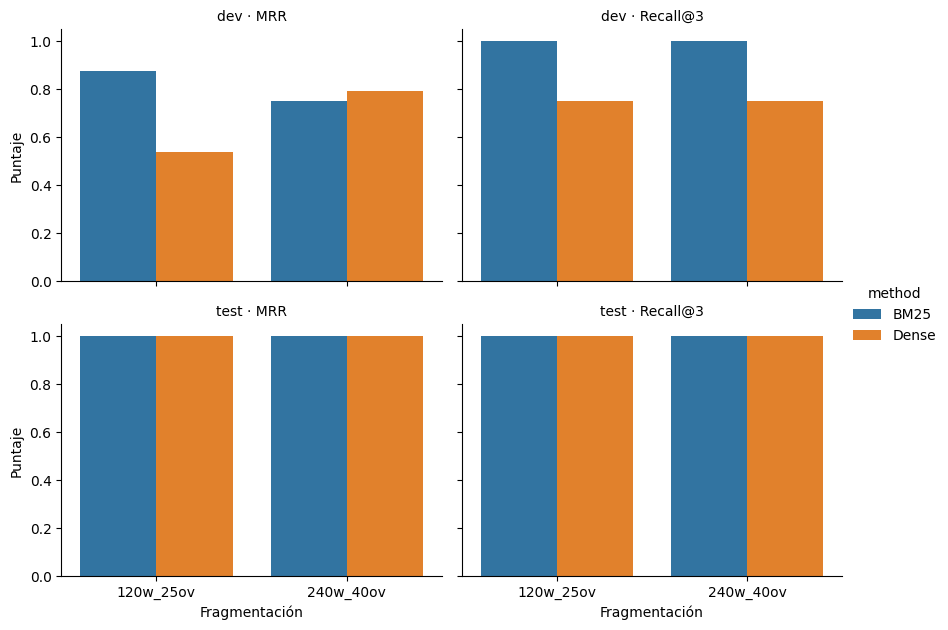

In [8]:
dev_results = results_df[results_df["split"] == "dev"].copy()
best_dev = dev_results.sort_values(["MRR", "Recall@3"], ascending=False).iloc[0]
dense_dev = dev_results[dev_results["method"] == "Dense"].sort_values(["MRR", "Recall@3"], ascending=False).iloc[0]
BEST_CONFIG = dense_dev["config"]
print(f"Mejor combinación global en consultas de selección: {best_dev['method']} / {best_dev['config']} (MRR={best_dev['MRR']:.3f})")
print(f"Configuración densa para chatbot: {BEST_CONFIG} (MRR dev={dense_dev['MRR']:.3f})")
print("La selección usa solo dev; la tabla test queda reservada para estimar el comportamiento fuera de selección.")

plot_df = results_df.melt(id_vars=["config", "split", "method"], value_vars=["MRR", "Recall@3"], var_name="metric", value_name="score")
g = sns.catplot(data=plot_df, x="config", y="score", hue="method", col="metric", row="split", kind="bar", height=3.2, aspect=1.35, sharey=True)
g.set_axis_labels("Fragmentación", "Puntaje")
g.set_titles("{row_name} · {col_name}")
plt.show()

## Auditoría cualitativa de recuperación

Las métricas resumen pocas consultas y no explican los fallos. En la siguiente celda se muestran para cada pregunta de prueba las fuentes esperadas y las primeras fuentes recuperadas. Revisa especialmente si un título general aparece por encima de una página específica, si el texto extraído está incompleto y si las consultas usan vocabulario no presente en las páginas.

In [9]:
test_ranking = rankings[(BEST_CONFIG, "test", "Dense")]
for query, retrieved in zip(TEST_QUERIES, test_ranking):
    print(f"\nPregunta: {query['question']}")
    print(f"Fuentes relevantes anotadas: {query['relevant']}")
    print(f"Primeras fuentes recuperadas: {retrieved[:3]}")
    print(f"Acierto en top-3: {bool(set(query['relevant']) & set(retrieved[:3]))}")


Pregunta: ¿Qué dimensiones contempla el acompañamiento a estudiantes?
Fuentes relevantes anotadas: ['acompanamiento']
Primeras fuentes recuperadas: ['acompanamiento', 'reglamento_posgrado_res_1691', 'servicios_posgrado']
Acierto en top-3: True

Pregunta: ¿Qué modifica la Resolución 1691 de 2026 del reglamento de posgrado?
Fuentes relevantes anotadas: ['reglamento_posgrado_res_1691']
Primeras fuentes recuperadas: ['reglamento_posgrado_res_1691', 'acompanamiento', 'admisiones_posgrado']
Acierto en top-3: True

Pregunta: ¿Qué servicios y recursos tiene la biblioteca universitaria?
Fuentes relevantes anotadas: ['biblioteca']
Primeras fuentes recuperadas: ['biblioteca', 'portal_estudiantes', 'acompanamiento']
Acierto en top-3: True

Pregunta: ¿Dónde empiezo para encontrar información para estudiantes de Icesi?
Fuentes relevantes anotadas: ['portal_estudiantes']
Primeras fuentes recuperadas: ['portal_estudiantes', 'biblioteca', 'reglamento_posgrado_res_1691']
Acierto en top-3: True

Pregunt

## Generación condicionada por recuperación

Se utiliza un modelo instruct pequeño que puede descargarse públicamente desde Hugging Face, sin una clave de API. La respuesta recibe únicamente los primeros fragmentos recuperados, debe reconocer cuándo el contexto no alcanza y no debe presentar fechas o reglas no citadas como hechos. La lista de referencias se adjunta desde los metadatos recuperados para que los enlaces no dependan de que el modelo los reproduzca correctamente.

**Importante:** encontrar una referencia no demuestra que la respuesta sea correcta. Comprueba el contenido contra la página oficial.

In [10]:
from transformers import AutoModelForCausalLM, AutoTokenizer

GENERATION_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(GENERATION_MODEL_NAME)
model_dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else (torch.float16 if torch.cuda.is_available() else torch.float32)
generator = AutoModelForCausalLM.from_pretrained(
    GENERATION_MODEL_NAME,
    torch_dtype=model_dtype,
    device_map="auto",
)
print(f"Modelo de generación cargado: {GENERATION_MODEL_NAME} ({model_dtype})")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelo de generación cargado: Qwen/Qwen2.5-1.5B-Instruct (torch.bfloat16)


In [11]:
ACTIVE_CHUNKS = chunk_sets[BEST_CONFIG]
ACTIVE_EMBEDDINGS = embeddings_by_config[BEST_CONFIG]

def retrieve_for_chat(question, k=4):
    query_embedding = embedding_model.encode([question], convert_to_numpy=True, normalize_embeddings=True)
    scores = (ACTIVE_EMBEDDINGS @ query_embedding[0]).reshape(-1)
    best_indices = np.argsort(scores)[::-1][:k]
    return [(ACTIVE_CHUNKS[index], float(scores[index])) for index in best_indices]

def generate_answer(question, history=None):
    out_of_scope = re.search(r"\b(calendario|fechas académicas|fecha límite de matrícula)\b", question.lower())
    if out_of_scope:
        return "Este prototipo no incluye un calendario académico oficial verificado. Consulta directamente los canales oficiales de Icesi para esa información."
    retrieved = retrieve_for_chat(question, k=4)
    context_blocks = []
    seen_sources = set()
    cited_sources = []
    for number, (chunk, score) in enumerate(retrieved, start=1):
        context_blocks.append(f"[Fuente {number}] {chunk['title']}\n{chunk['text']}\nURL: {chunk['url']}")
        if chunk["source_id"] not in seen_sources:
            cited_sources.append(chunk)
            seen_sources.add(chunk["source_id"])
    context = "\n\n".join(context_blocks)
    recent_history = ""
    for message in (history or [])[-4:]:
        if isinstance(message, dict) and message.get("content"):
            recent_history += f"{message.get('role', 'user')}: {message['content']}\n"
        elif isinstance(message, (list, tuple)) and len(message) == 2:
            user_message, assistant_message = message
            recent_history += f"user: {user_message or ''}\nassistant: {assistant_message or ''}\n"
    prompt_messages = [
{"role": "system", "content": "Eres un asistente informativo para personas interesadas en los servicios de posgrado de la Universidad Icesi. Responde en español con claridad y brevedad. Basa cada afirmación únicamente en el contexto proporcionado. Si el contexto no contiene la respuesta, dilo explícitamente y recomienda consultar directamente a Icesi; no inventes normas, fechas, tarifas ni procedimientos. El corpus incluye la Resolución 1691 de 2026, que modifica el reglamento de posgrado, pero no el reglamento completo: responde preguntas sobre esa resolución solo cuando el contexto lo sustente y aclara ese alcance. No respondas preguntas sobre calendarios ni fechas académicas. Cita las afirmaciones con [Fuente 1], [Fuente 2], etc., usando solo las fuentes del contexto."},
        {"role": "user", "content": f"Historial reciente:\n{recent_history or '(sin historial)'}\n\nContexto recuperado:\n{context}\n\nPregunta actual: {question}"},
    ]
    prompt = tokenizer.apply_chat_template(prompt_messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(next(generator.parameters()).device)
    with torch.no_grad():
        output = generator.generate(**inputs, max_new_tokens=180, do_sample=False, repetition_penalty=1.05)
    answer = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    references = "\n\n**Fuentes recuperadas (verifica el contenido):**\n" + "\n".join(
        f"- [{source['title']}]({source['url']})" for source in cited_sources
    )
    return answer + references

## Prueba manual y límites de respuesta

Haz preguntas sobre una fuente visible y luego una fuera del corpus (por ejemplo, una fecha de matrícula o un artículo del reglamento). Evalúa si el asistente cita fuentes pertinentes, se mantiene dentro del alcance y reconoce la falta de información. El sistema no puede validar por sí mismo si una página institucional cambió después de la descarga.

In [12]:
demo_questions = [
    "¿Qué dimensiones tiene el ecosistema de acompañamiento a estudiantes?",
    "¿Dónde puedo hablar con alguien sobre un programa de posgrado?",
    "¿Cuál es la fecha límite de matrícula para el próximo semestre?",
]
for question in demo_questions:
    print("\n" + "=" * 90)
    print("Pregunta:", question)
    print(generate_answer(question))


Pregunta: ¿Qué dimensiones tiene el ecosistema de acompañamiento a estudiantes?
El ecosistema de acompañamiento a estudiantes de la Universidad Icesi tiene cuatro dimensiones fundamentales:

1. Académica: Se enfoca en el desarrollo académico de los estudiantes, incluyendo estrategias para mejorar la permanencia y el éxito académico.

2. Socioemocional: Se centra en el desarrollo de habilidades sociales y emocionales, ayudando a los estudiantes a manejar mejor sus emociones y relaciones interpersonales.

3. Vocacional: Se dirige a la exploración y consolidación de intereses, habilidades y valores de los estudiantes, facilitando su elección de carreras y trayectorias formativas.

4. Inclusión: Se enfoca en la integración de los estudiantes en la vida universitaria, abordando las condiciones que pueden afectar su adaptación y éxito académ

**Fuentes recuperadas (verifica el contenido):**
- [Ecosistema de acompañamiento a estudiantes](https://www.icesi.edu.co/decanatura-de-innovacion-educ

## Interfaz conversacional para la demostración

La última celda publica una interfaz Gradio temporal apta para Colab. Para la entrega en video, muestra la carga de la interfaz y al menos una pregunta respondida con sus referencias; incluye también una pregunta fuera del alcance para evidenciar cómo maneja la falta de contexto. No compartas información personal en la demostración.

**Video uso del chatbot:** [Abrir la carpeta de demostración en Google Drive](https://drive.google.com/drive/folders/1qEFrMWcC3_bGeyFxnBqv2s1LmACvNkn6)

In [13]:
import gradio as gr

def gradio_chat(message, history):
    return generate_answer(message, history)

demo = gr.ChatInterface(
    fn=gradio_chat,
    title="Asistente de servicios de posgrado · Icesi",
    description="Prototipo académico basado en páginas públicas e incluye la Resolución 1691 de 2026; no contiene el reglamento completo ni el calendario académico. Consulta los enlaces oficiales.",
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3832380fca1cc3d991.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Análisis y conclusiones

### Resultados de recuperación guardados

La ejecución reflejada en las salidas del notebook usó 4 consultas de selección (`dev`) y 5 consultas reservadas (`test`). `Recall@3` mide si una fuente relevante aparece entre las tres primeras; `MRR` recompensa que aparezca en una posición más alta.

| Partición | Fragmentación | Método | Recall@3 | MRR |
|---|---|---:|---:|---:|
| Selección | 120w_25ov | BM25 | 1.000 | 0.875 |
| Selección | 120w_25ov | Dense | 0.750 | 0.536 |
| Selección | 240w_40ov | BM25 | 1.000 | 0.750 |
| Selección | 240w_40ov | Dense | 0.750 | 0.792 |
| Prueba | 120w_25ov | BM25 | 1.000 | 1.000 |
| Prueba | 120w_25ov | Dense | 1.000 | 1.000 |
| Prueba | 240w_40ov | BM25 | 1.000 | 1.000 |
| Prueba | 240w_40ov | Dense | 1.000 | 1.000 |

En selección, BM25 con fragmentos de 120 palabras obtuvo el mayor MRR global (0.875) y Recall@3 de 1.000. Para la configuración densa del chatbot se eligieron 240 palabras porque fue la mejor variante densa en `dev` (MRR 0.792); esto no significa que Dense superara a BM25 en conjunto. En `test`, las cuatro combinaciones alcanzaron 1.000 en ambas métricas, de modo que esta muestra no permite distinguirlas. El resultado es alentador, pero no demuestra superioridad general: solo hay cinco consultas de prueba y las etiquetas de relevancia son manuales.

El tamaño del fragmento tuvo efectos distintos según el método. Al pasar de 120 a 240 palabras, Dense mantuvo Recall@3 en 0.750 y subió su MRR de 0.536 a 0.792; BM25 mantuvo Recall@3 en 1.000 y bajó su MRR de 0.875 a 0.750. Por tanto, no hay un tamaño ganador para ambos recuperadores. Estas métricas evalúan recuperación, no la exactitud ni la completitud de las respuestas generadas.

El chatbot combina rankings BM25 y Dense con RRF y muestra citas textuales verificadas contra los fragmentos recuperados. Esa verificación confirma que la cita está en el corpus, pero no garantiza que la respuesta cubra todos los aspectos de la pregunta. La revisión cualitativa debe contrastar cada afirmación y enlace con la fuente; si no hay evidencia suficiente, el asistente debe abstenerse. El corpus incluye páginas públicas y la Resolución 1691 de 2026, pero no el reglamento completo ni el calendario académico.

Como siguientes pasos, conviene ampliar las consultas anotadas, añadir evaluadores humanos, inspeccionar errores de extracción y completar el corpus con documentos oficiales pertinentes antes de extraer conclusiones más amplias.

### Limitaciones

- Las páginas son dinámicas y la extracción puede omitir contenido cargado por JavaScript.
- El conjunto de consultas es pequeño y las fuentes relevantes se anotaron manualmente.
- La similitud semántica y las métricas de recuperación no garantizan factualidad de la generación.
- El corpus incluye una resolución que modifica el reglamento, pero no el reglamento completo ni el calendario académico; el asistente no es un canal institucional ni reemplaza asesoría oficial.
- Los modelos descargados pueden cambiar de versión y sus respuestas no son deterministas en todos los entornos.
